# 35 · Reliability and durable runs: retries, idempotency and a kill drill
Level L6 · Part 6 · core · ~40 min · builds on 11, 13, 34

## Goal
Make the refund step safe to retry, and make the run survive a crash. Two parts. **Retries**: a payment that times out is retried with a policy
(attempts, backoff), and the key that identifies the payment makes a retry safe. **A kill drill**: a worker process records the payment and then
dies; a new process resumes the same run from its saved checkpoint, and the money moves once. The worker dies with a hard exit that skips all
cleanup, the way a killed process does.

## Why it matters
A payment API times out after the money has moved, and the agent cannot tell. A retry then pays twice. A worker that dies in the middle of a run
loses its place, and a restart either repeats the payment or drops the refund. Both are money bugs.

| No idempotency key and no checkpoint | With both |
|---|---|
| A retry after a timeout pays twice | The key is the run id; a retry pays nothing new |
| A crash restarts the run from the top | The run resumes from the last saved step |
| Nobody knows whether the payment happened | The ledger holds one row per run, which is the answer |

## The idea
A **retry policy** says how many attempts a step gets and how long to wait between them, with jitter so many workers do not retry together. An
**idempotency key** is an identifier that makes the same request safe to repeat: the payment is recorded under the run id, and a second insert with
the same key does nothing. A **checkpoint** saves the state after each step under a thread id; a new process reads it and continues.

## Picture
`show_mermaid` is a course helper (in `graph_view.py`) that draws a Mermaid flowchart, written as text, inside the notebook.

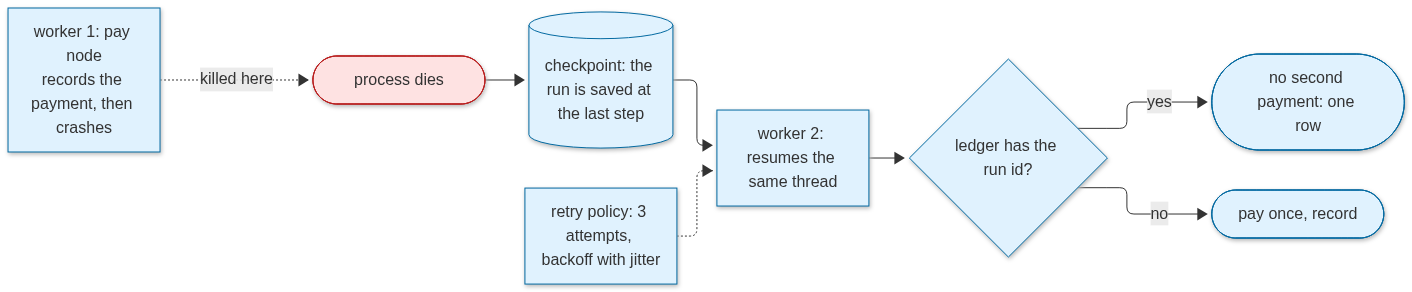

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  W1["worker 1: pay node<br/>records the payment, then crashes"] -. "killed here" .-> X(["process dies"])
  X --> C[("checkpoint: the run is saved at the last step")]
  C --> W2["worker 2: resumes the same thread"]
  W2 --> K{"ledger has the run id?"}
  K -->|yes| D(["no second payment: one row"])
  K -->|no| P(["pay once, record"])
  R["retry policy: 3 attempts, backoff with jitter"] -.-> W2
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef stop fill:#fee2e2,stroke:#b91c1c
  class W1,C,W2,K,P,R code
  class X stop
  class D code
""")

## Step by step
**Step 1 · a payment that times out, with a retry policy (no call).** The payment service times out on its first call, after the money has moved in
its own records. The refund step is one node of the graph, called `pay`. Its ledger key is the run id, so the retry is safe: the second attempt
finds the row already there and records nothing new. The setup first: a provider stand-in, and a ledger (a SQLite table with one row per run id).

In [2]:
import sqlite3
from pathlib import Path

from langgraph.graph import END, START, StateGraph
from langgraph.types import RetryPolicy
from typing_extensions import TypedDict

LAB = Path("../../../data/lg35").resolve()
LAB.mkdir(parents=True, exist_ok=True)
PAYMENT_SERVICE = {"moved": [], "calls": 0, "timeouts_left": 1}  # the provider: moves money, may time out after it does
LEDGER = sqlite3.connect(LAB / "ledger.db")
LEDGER.execute("CREATE TABLE IF NOT EXISTS ledger (run_id TEXT PRIMARY KEY, amount REAL)")
LEDGER.execute("DELETE FROM ledger")  # a clean run: no rows from an earlier try
LEDGER.commit()


class RefundState(TypedDict):
    run_id: str
    amount: float
    status: str

The `pay` function is the node. It writes the ledger row first, then the provider moves the money, then the reply is lost in a timeout. The
`INSERT OR IGNORE` is the idempotency key at work: a second insert for the same run id is ignored, not added.

In [3]:
def pay(state: RefundState) -> dict:
    PAYMENT_SERVICE["calls"] += 1
    LEDGER.execute("INSERT OR IGNORE INTO ledger VALUES (?, ?)", (state["run_id"], state["amount"]))
    LEDGER.commit()
    if state["run_id"] not in PAYMENT_SERVICE["moved"]:  # the provider also keys the payment: one move per run
        PAYMENT_SERVICE["moved"].append(state["run_id"])  # the money has moved, even if the reply is lost
    if PAYMENT_SERVICE["timeouts_left"] > 0:
        PAYMENT_SERVICE["timeouts_left"] -= 1
        raise TimeoutError("the payment service did not reply in time")  # the reply is lost after the move
    return {"status": "paid"}

`RetryPolicy` is LangGraph's retry setting for one node: how many attempts, the first wait, the growth factor, whether to add jitter, and which
error to retry. We attach it to `pay` and run the refund once.

In [4]:
g = StateGraph(RefundState)
g.add_node("pay", pay, retry_policy=RetryPolicy(max_attempts=3, initial_interval=0.1, backoff_factor=2.0, jitter=True,
                                                 retry_on=TimeoutError))
g.add_edge(START, "pay").add_edge("pay", END)
refund_app = g.compile()
out = refund_app.invoke({"run_id": "refund-1003", "amount": 89.5, "status": ""})
print("status:", out["status"], "· pay() calls:", PAYMENT_SERVICE["calls"], "· money moves:", len(PAYMENT_SERVICE["moved"]),
      "· ledger rows:", LEDGER.execute("SELECT COUNT(*) FROM ledger").fetchone()[0])

status: paid · pay() calls: 2 · money moves: 1 · ledger rows: 1


**Step 2 · the settings in one place (no call).** A retry without a limit would loop forever, and a call without a timeout can hang. The settings
are kept in one dict and printed. The stand-in provider has no clock, so `call_timeout_s` is recorded here but not enforced; a real HTTP client
takes it as its timeout.

In [5]:
POLICY = {"max_attempts": 3, "initial_interval_s": 0.1, "backoff_factor": 2.0, "jitter": True, "call_timeout_s": 5.0}
for name, value in POLICY.items():
    print(f"{name:<18} {value}")
waits = [POLICY["initial_interval_s"] * POLICY["backoff_factor"] ** i for i in range(POLICY["max_attempts"] - 1)]
print("waits between attempts (before jitter):", waits)

max_attempts       3
initial_interval_s 0.1
backoff_factor     2.0
jitter             True
call_timeout_s     5.0
waits between attempts (before jitter): [0.1, 0.2]


**Step 3 · the worker that will be killed (no call).** The kill drill needs a separate process, so the worker is a script. It builds the same
refund run with a file-backed checkpointer (`SqliteSaver`, which saves each step to `runs.db`). Given the argument `crash`, it records the payment
and then exits hard with `os._exit`, before the step is saved.

In [6]:
%%writefile ../../../data/lg35/worker.py
"""A refund worker for the kill drill (lesson 35). With the argument 'crash' it records the payment, then dies before the step is saved."""
import os
import sqlite3
import sys
from pathlib import Path
from typing_extensions import TypedDict

from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph

LAB = Path(__file__).resolve().parent
DB = LAB / "runs.db"
CRASH = "crash" in sys.argv[2:]  # the drill's first worker dies after recording the payment


class RefundState(TypedDict):
    run_id: str
    amount: float
    status: str


def pay(state: RefundState) -> dict:
    with sqlite3.connect(DB) as db:  # the ledger: one row per run id (the idempotency key)
        db.execute("CREATE TABLE IF NOT EXISTS ledger (run_id TEXT PRIMARY KEY, amount REAL)")
        db.execute("INSERT OR IGNORE INTO ledger VALUES (?, ?)", (state["run_id"], state["amount"]))
    if CRASH:
        os._exit(3)  # hard exit: the money is recorded, the step is not saved, and no cleanup runs
    return {"status": "paid"}


def build(saver):
    g = StateGraph(RefundState)
    g.add_node("pay", pay)
    g.add_edge(START, "pay").add_edge("pay", END)
    return g.compile(checkpointer=saver)


if __name__ == "__main__":
    run_id = sys.argv[1]
    with sqlite3.connect(DB, check_same_thread=False) as conn:
        app = build(SqliteSaver(conn))
        config = {"configurable": {"thread_id": run_id}}
        resumed = bool(app.get_state(config).next)  # a saved, unfinished run: resume it, with no new input
        if resumed:
            result = app.invoke(None, config)
        else:
            result = app.invoke({"run_id": run_id, "amount": 89.5, "status": ""}, config)
        print("status:", result["status"], "· resumed:", resumed)

Overwriting ../../../data/lg35/worker.py


**Step 4 · the kill drill: crash, restart, check (no call).** The first worker is started with `crash` and dies mid-run. Its exit code shows the
hard exit. The second worker starts in a new process with the same run id, resumes the saved thread, and finishes. The ledger is then checked:
one row.

In [7]:
import subprocess
import sys

WORKER = LAB / "worker.py"
DB_PATH = LAB / "runs.db"
if DB_PATH.exists():
    DB_PATH.unlink()  # a clean drill: no saved runs from an earlier try

crashed = subprocess.run([sys.executable, str(WORKER), "refund-2207", "crash"], capture_output=True, text=True, cwd=str(LAB))
print("worker 1 exit code:", crashed.returncode, "· 3 is the worker's hard exit, after it recorded the payment")

resumed = subprocess.run([sys.executable, str(WORKER), "refund-2207"], capture_output=True, text=True, cwd=str(LAB))
print("worker 2:", resumed.stdout.strip() or resumed.stderr.strip().splitlines()[-1][:120])
with sqlite3.connect(DB_PATH) as db:
    rows = db.execute("SELECT run_id, amount FROM ledger WHERE run_id = 'refund-2207'").fetchall()
print("ledger rows for refund-2207:", rows, "· paid once:", len(rows) == 1)

worker 1 exit code: 3 · 3 is the worker's hard exit, after it recorded the payment


worker 2: status: paid · resumed: True
ledger rows for refund-2207: [('refund-2207', 89.5)] · paid once: True


**Step 5 · a third start after the run finished (no call).** Restarts can also come after a run has ended. The same run id is started once more,
in a new process, and the ledger is checked again.

In [8]:
third = subprocess.run([sys.executable, str(WORKER), "refund-2207"], capture_output=True, text=True, cwd=str(LAB))
print("worker 3:", third.stdout.strip() or third.stderr.strip().splitlines()[-1][:120])
with sqlite3.connect(DB_PATH) as db:
    print("ledger rows for refund-2207 after worker 3:", db.execute(
        "SELECT COUNT(*) FROM ledger WHERE run_id = 'refund-2207'").fetchone()[0])

worker 3: status: paid · resumed: False
ledger rows for refund-2207 after worker 3: 1


## At real scale
- A retry policy is set per step: a payment gets few attempts with backoff, a lookup can get more. Keep the policy in one place and log each retry
  → lesson 33 (observability).
- Every side effect is keyed, and the key is the run id, so any retry or restart is safe. Test the key with a kill drill before release → lesson 32
  (evals in CI).
- A durable run keeps its state in a database, not in a process. Temporal, a workflow engine, resumes a run by replaying its saved event history;
  its rule is the same as the key here: a side effect can run twice, so it must be idempotent → lesson 38 (capstone).

## Decision guide
| Situation | Approach | Why |
|---|---|---|
| A call that may time out and moves money | retry with the run id as the key | the key makes the retry a no-op in the ledger |
| A read that changes nothing (order status) | retry with backoff; no key needed | repeating a read is harmless |
| The same error on every attempt (a bad request) | stop after the attempt limit and escalate | a retry cannot fix a bad request |
| A worker may die at any step | checkpoint each step under a thread id | a restart resumes instead of repeating |
| You cannot show a restart is safe | run a kill drill before release | a drill that never kills a process proves nothing |

## What just happened
- Step 1: `pay()` ran 2 times, the money moved once, and the ledger holds 1 row: the retry paid nothing new.
- Step 2: the waits between attempts are 0.1 s and 0.2 s, before jitter.
- Step 4: worker 1 exited with code 3 after it recorded the payment; worker 2 resumed (`resumed: True`) and the ledger holds one row for refund-2207.
- Step 5: a third start after the run finished left the ledger at 1 row.

## Common mistakes
1. **A retry with no key.** Without the key, each retry is a new payment. Each mistake below is shown with the real result. Here a plain insert
   for a run id that is already in the ledger fails. The fix is the key: `INSERT OR IGNORE`, as `pay` uses.

In [9]:
try:
    LEDGER.execute("INSERT INTO ledger VALUES (?, ?)", ("refund-1003", 89.5))  # a plain insert, as a naive retry would do
except sqlite3.IntegrityError as err:
    print(type(err).__name__, "·", str(err).splitlines()[0])

IntegrityError · UNIQUE constraint failed: ledger.run_id


2. **A payment before the checkpoint is saved.** If the process dies between the payment and the save, the run repeats. The key makes the repeat
   safe: the same run id is called again below, and the money does not move a second time.

In [10]:
out = pay({"run_id": "refund-1003", "amount": 89.5, "status": ""})  # the repeat a restart would cause
print("repeat:", out, "· money moves:", len(PAYMENT_SERVICE["moved"]))

repeat: {'status': 'paid'} · money moves: 1


3. **A drill that never kills anything.** A worker run without the `crash` argument exits normally, so a drill that only runs it tests nothing
   about restarts. Kill the process.

In [11]:
no_kill = subprocess.run([sys.executable, str(WORKER), "refund-3001"], capture_output=True, text=True, cwd=str(LAB))
print("drill without a kill: exit code", no_kill.returncode, "· nothing was killed, so no restart was tested")

drill without a kill: exit code 0 · nothing was killed, so no restart was tested


## Try it
Write `backoff_waits(attempts, initial, factor)` that returns the list of waits between attempts, before jitter. Test it on `(3, 0.1, 2.0)`. No model call
is needed.

In [12]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [13]:
def backoff_waits(attempts: int, initial: float, factor: float) -> list[float]:
    return [initial * factor ** i for i in range(attempts - 1)]


print(backoff_waits(3, 0.1, 2.0))  # [0.1, 0.2]

[0.1, 0.2]


## Key terms
- **Backoff** — the growing wait between retry attempts (here 0.1 s, then 0.2 s).
- **Checkpoint** — the saved state of a run after a step, so a new process can continue it.
- **Idempotency key** — an identifier that makes a repeated request safe; here, the run id.
- **Jitter** — a random part added to each wait, so many workers do not retry at the same moment.
- **Kill drill** — a test that stops a worker process in the middle of a run and checks the restart.
- **Retry policy** — the rule for one step: how many attempts, the waits, and which errors to retry.
- **Thread id** — the name of one saved run in the checkpointer; the same id resumes the run.

## Recap
- A retry policy sets the attempts and the backoff for a step; the backoff has jitter.
- An idempotency key (the run id) makes a retry or a restart safe.
- A checkpoint lets a new process resume the run, and a kill drill shows that the money moves once.

**Interview:** "The worker that pays a refund dies after the payment and before it saves. What happens when it restarts?" Strong answer: "The payment was
recorded under the run's key, so the restarted worker resumes from the saved checkpoint, finds the key and pays nothing new. I test that with a
drill that kills the process."